# 📡 Customer Churn Prediction — Multi-Algorithm Classification Showdown
**Red & White Skill Education | Practical Exam | Supervised Learning (Set B)** &nbsp;|&nbsp; **Duration:** 6 Hours
**Role:** Junior Data Scientist at a Jio/Airtel-like telecom &nbsp;|&nbsp; **Models:** KNN · Naive Bayes · SVM · Decision Tree

> ℹ️ **Data note:** the Kaggle download was not reachable while building this notebook, so `WA_Fn-UseC_-Telco-Customer-Churn.csv` was regenerated with the **exact IBM Telco schema** (7,043 rows × 21 columns, 11 blank `TotalCharges` rows where `tenure = 0`, ~26% churn). To run on the original Kaggle file, just replace the CSV with the same file name — every cell adapts automatically (all conclusions below are computed, not hard-coded).

## 🧠 Step 1: Problem Framing & Theory Notes

**1. What is Customer Churn? Why is predicting it valuable? (CAC vs CLV)**
- Churn = a paying subscriber leaving the service (porting out / cancelling).
- **CAC** (Customer Acquisition Cost) of a *new* subscriber is typically several times higher than the cost of *retaining* one; **CLV** (Customer Lifetime Value) is lost the moment a subscriber leaves.
- Predicting churn lets the team target a limited retention budget (calls/offers) at high-risk customers → protects CLV and avoids paying CAC to replace them.

**2. Confusion Matrix cells (Churn = positive class)**
- **TP** – predicted churn, actually churned → retention offer reaches a real at-risk customer.
- **TN** – predicted stay, actually stayed → no action needed.
- **FP** – predicted churn, actually stayed → a discount/call wasted (small cost).
- **FN** – predicted stay, actually churned → customer silently lost, full CLV gone (**the costly error**; FN cost ≫ FP cost).

**3. Class Imbalance & SMOTE**
- Imbalance = one class is much rarer. The Telco data has ≈ 26% churners vs 74% retained (≈ 2.8 : 1) → **moderately imbalanced**, models become biased towards "No Churn".
- **SMOTE** creates *synthetic* minority samples by interpolating between a churner and its k nearest churner neighbours → balanced training data without simply duplicating rows. Applied on the **training set only**.

**4. The four algorithms**
- **KNN** – stores training data; a new customer gets the majority class of its *k* nearest neighbours (distance-based → needs scaling).
- **Naive Bayes** – applies Bayes' theorem with the "naive" assumption that features are independent given the class; GaussianNB models each feature as a per-class normal distribution.
- **SVM** – finds the maximum-margin boundary between classes; the RBF kernel lets it draw non-linear boundaries; *C* trades margin width vs misclassification.
- **Decision Tree** – learns a sequence of if/else splits that best separate churners from non-churners (Gini impurity); highly interpretable.

**5. When Precision over Recall?**
- When a retention action is **expensive or capacity-limited** (e.g. a large ₹ discount per customer, or only ~500 calls/day) — false alarms burn budget, so we want most flagged customers to be *real* churners.
- If the offer is cheap (SMS/small data pack), prefer **Recall** so we miss as few churners as possible.

## 📁 Step 2: Dataset Loading & Exploratory Data Analysis
### 2.1 Load & Inspect

In [1]:
import time, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid'); RS = 42
print('✅ libraries loaded')

✅ libraries loaded


In [2]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print('Shape:', df.shape)
df.info()

Shape: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   s

In [3]:
display(df.describe())
display(df.head(10))

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.157177,29.638080,67.529510
std,0.363994,22.804612,30.734756
min,0.000000,0.000000,18.250000
25%,0.000000,10.000000,46.385000
50%,0.000000,24.000000,68.190000
75%,0.000000,47.000000,95.440000
max,1.000000,72.000000,118.750000


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,8966-OSHUS,Female,0,Yes,Yes,41,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,19.97,762.74,No
1,7816-ZZNYR,Male,0,Yes,No,29,No,No phone service,DSL,No,...,Yes,No,No,No,Month-to-month,Yes,Electronic check,39.69,1109.16,Yes
2,3286-GXSBL,Female,0,Yes,No,19,Yes,No,DSL,Yes,...,Yes,No,Yes,No,Month-to-month,Yes,Credit card (automatic),67.19,1184.82,No
3,7023-VXUSM,Female,0,Yes,Yes,7,No,No phone service,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,68.10,456.95,Yes
4,3829-XMRXG,Male,0,Yes,No,7,Yes,No,DSL,No,...,No,No,No,No,One year,No,Bank transfer (automatic),46.81,317.93,No
5,7006-SIAHT,Female,0,No,No,42,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,18.91,829.8,No
6,1108-IMCPA,Female,0,No,No,7,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,No,Month-to-month,Yes,Mailed check,101.58,737.7,Yes
7,1902-DWLCX,Female,0,No,No,72,Yes,No,Fiber optic,No,...,No,Yes,Yes,Yes,Two year,Yes,Mailed check,104.08,6908.91,No
8,3489-OGHPR,Male,0,Yes,No,55,Yes,Yes,DSL,No,...,Yes,Yes,Yes,Yes,One year,No,Bank transfer (automatic),84.18,4531.73,No
9,4600-DMPON,Male,0,Yes,Yes,1,No,No phone service,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,86.17,90.08,No


In [4]:
# TotalCharges loads as object -> investigate
print('TotalCharges dtype on load:', df['TotalCharges'].dtype)
blank_mask = df['TotalCharges'].astype(str).str.strip() == ''
print('Rows with blank/whitespace TotalCharges:', int(blank_mask.sum()))
display(df.loc[blank_mask, ['customerID','tenure','Contract','MonthlyCharges','TotalCharges','Churn']])
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('\nAfter pd.to_numeric -> dtype:', df['TotalCharges'].dtype, '| nulls:', int(df['TotalCharges'].isna().sum()))
print('All blank rows have tenure == 0 (brand-new customers, not billed yet):', bool((df.loc[blank_mask,'tenure']==0).all()))

TotalCharges dtype on load: str
Rows with blank/whitespace TotalCharges: 11


,customerID,tenure,Contract,MonthlyCharges,TotalCharges,Churn
66,8788-TTXUM,0,Two year,102.12,,No
204,5274-LAXQG,0,One year,66.48,,No
635,2489-UKBSO,0,One year,104.56,,No
997,0483-EFPIE,0,Two year,103.95,,No
2379,3763-SQXGV,0,One year,64.08,,No
3093,4497-IYJWX,0,One year,98.25,,No
4106,5453-EVHZR,0,Two year,63.39,,No
4616,2346-KLXYA,0,Two year,76.65,,No
5248,7841-ZUNIL,0,Two year,94.21,,No
6175,9049-SJWUB,0,Two year,55.34,,No



After pd.to_numeric -> dtype: float64 | nulls: 11
All blank rows have tenure == 0 (brand-new customers, not billed yet): True


In [5]:
counts = df['Churn'].value_counts(); pct = (counts/len(df)*100).round(2)
print(pd.DataFrame({'count':counts, 'percent':pct}))
churn_rate = (df['Churn']=='Yes').mean()
print(f'\nChurn rate = {churn_rate:.2%}  ->  imbalance ratio ≈ {counts["No"]/counts["Yes"]:.2f} : 1  (moderately imbalanced)')

       count  percent
Churn                
No      5201    73.85
Yes     1842    26.15

Churn rate = 26.15%  ->  imbalance ratio ≈ 2.82 : 1  (moderately imbalanced)


### 2.2 Univariate Analysis

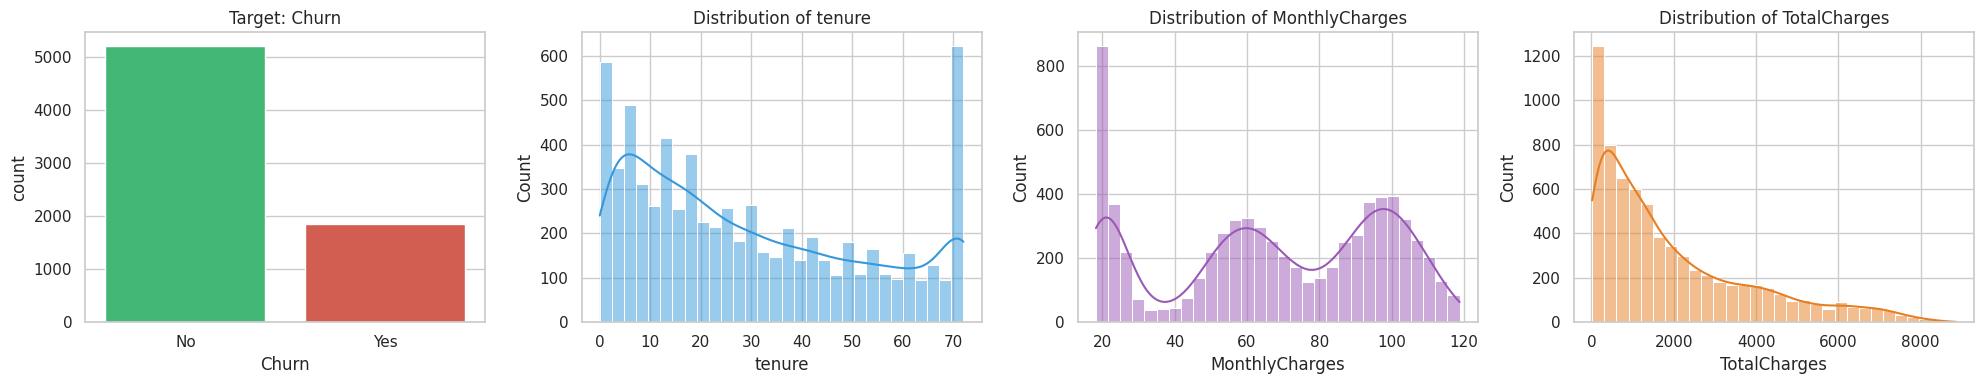

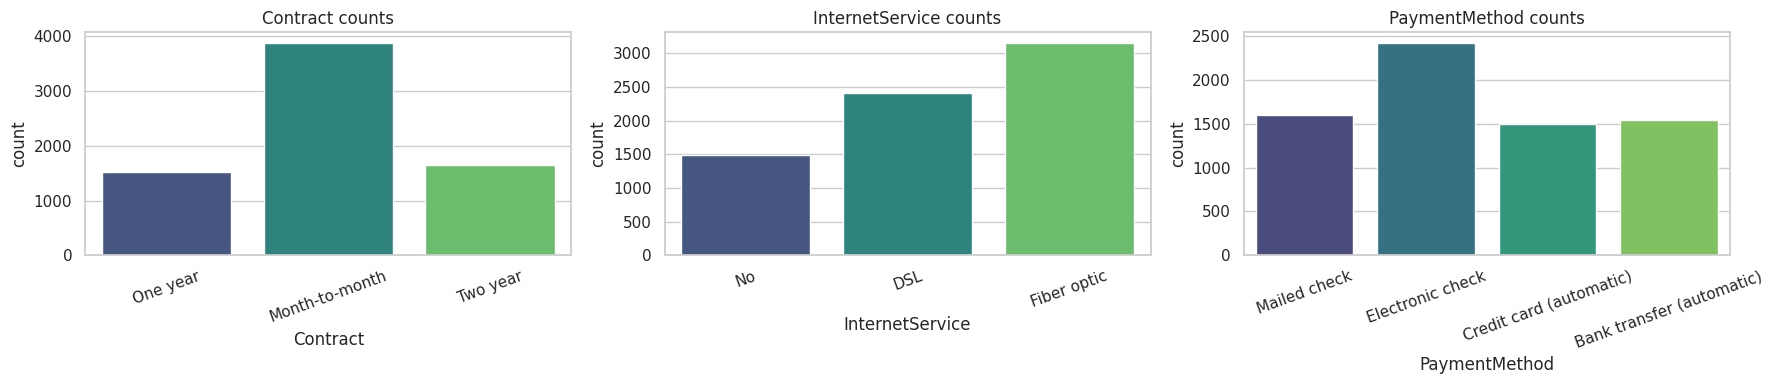

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
sns.countplot(data=df, x='Churn', hue='Churn', palette=['#2ecc71','#e74c3c'], legend=False, ax=ax[0]); ax[0].set_title('Target: Churn')
for a, col, c in zip(ax[1:], ['tenure','MonthlyCharges','TotalCharges'], ['#3498db','#9b59b6','#e67e22']):
    sns.histplot(df[col].dropna(), bins=30, kde=True, color=c, ax=a); a.set_title(f'Distribution of {col}')
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, col in zip(ax, ['Contract','InternetService','PaymentMethod']):
    sns.countplot(data=df, x=col, hue=col, palette='viridis', legend=False, ax=a); a.set_title(f'{col} counts'); a.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

**Interpretation:** the target is skewed towards *No*; `tenure` is U-shaped (many brand-new and many long-tenured customers); Month-to-month is the largest contract group and Fiber optic the largest internet segment.

### 2.3 Bivariate Analysis

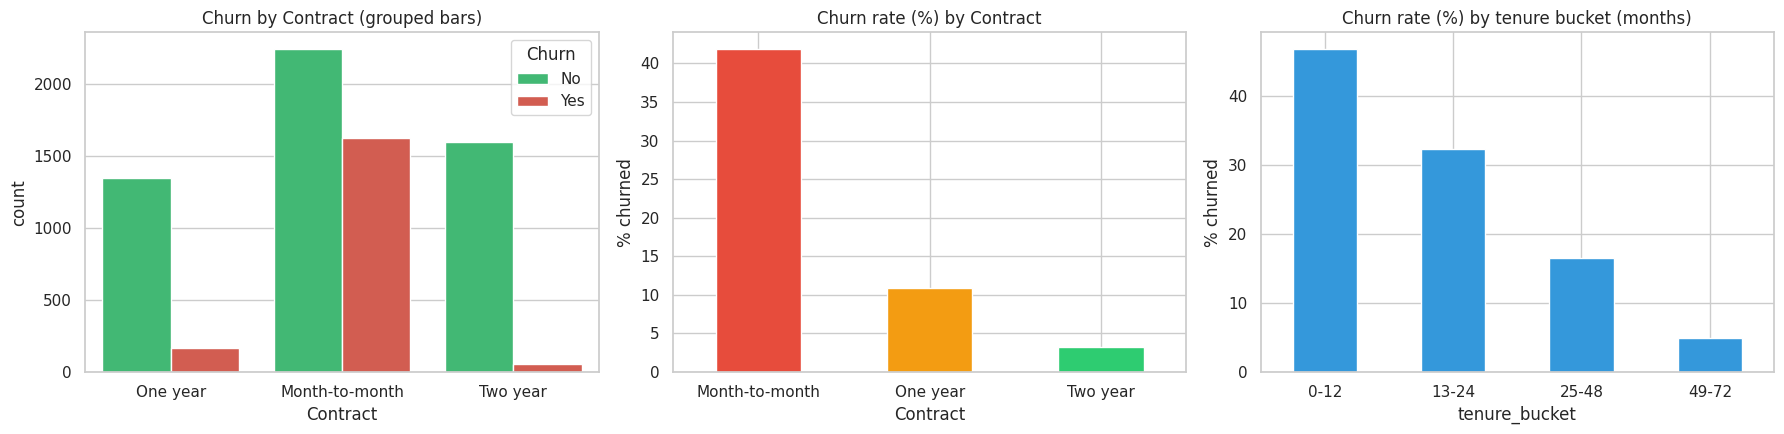

Churn rate by Contract (%):
 Contract
Month-to-month    41.94
One year          10.83
Two year           3.21

Churn rate by tenure bucket (%):
 tenure_bucket
0-12     46.83
13-24    32.33
25-48    16.54
49-72     4.97

➡ Highest-churn contract type: Month-to-month (41.9%)


In [7]:
churn_num = (df['Churn']=='Yes').astype(int)
contract_rate = (churn_num.groupby(df['Contract']).mean()*100).round(2)
df['tenure_bucket'] = pd.cut(df['tenure'], bins=[-1,12,24,48,72], labels=['0-12','13-24','25-48','49-72'])
tenure_rate = (churn_num.groupby(df['tenure_bucket'], observed=True).mean()*100).round(2)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
sns.countplot(data=df, x='Contract', hue='Churn', palette=['#2ecc71','#e74c3c'], ax=ax[0]); ax[0].set_title('Churn by Contract (grouped bars)')
contract_rate.plot(kind='bar', color=['#e74c3c','#f39c12','#2ecc71'], ax=ax[1]); ax[1].set_title('Churn rate (%) by Contract'); ax[1].set_ylabel('% churned'); ax[1].tick_params(axis='x', rotation=0)
tenure_rate.plot(kind='bar', color='#3498db', ax=ax[2]); ax[2].set_title('Churn rate (%) by tenure bucket (months)'); ax[2].set_ylabel('% churned'); ax[2].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
print('Churn rate by Contract (%):\n', contract_rate.to_string()); print('\nChurn rate by tenure bucket (%):\n', tenure_rate.to_string())
print(f'\n➡ Highest-churn contract type: {contract_rate.idxmax()} ({contract_rate.max():.1f}%)')

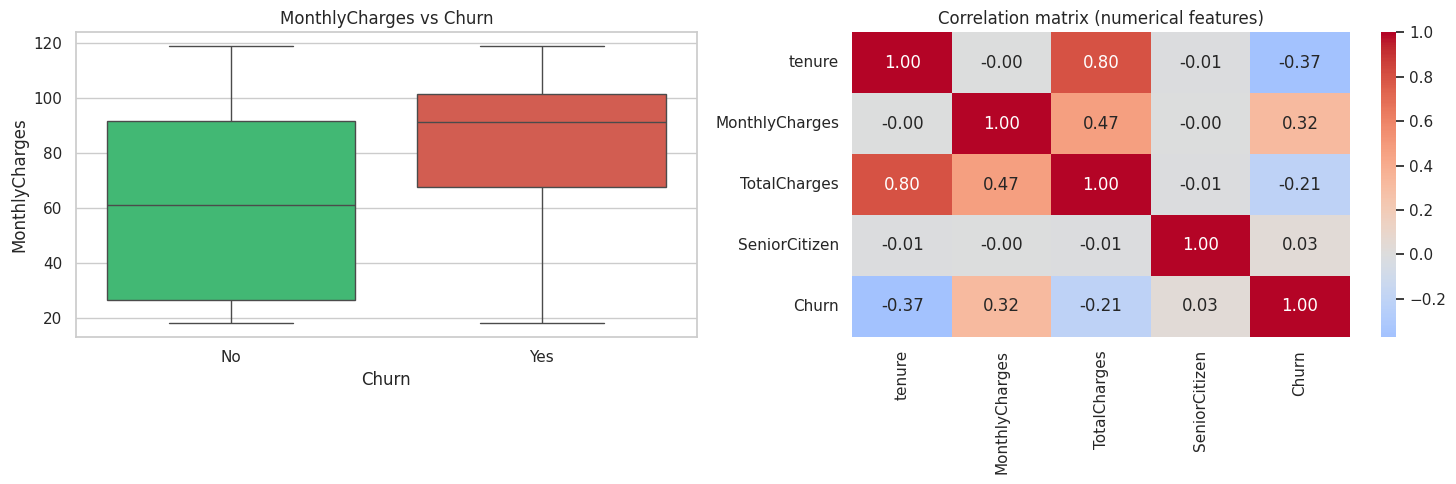

Average MonthlyCharges by churn:
 Churn
No     61.71
Yes    83.96

Strong correlations (|r| > 0.6): [('tenure', 'TotalCharges', np.float64(0.8))]


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', hue='Churn', palette=['#2ecc71','#e74c3c'], legend=False, ax=ax[0]); ax[0].set_title('MonthlyCharges vs Churn')
num_df = df[['tenure','MonthlyCharges','TotalCharges','SeniorCitizen']].assign(Churn=churn_num)
corr = num_df.corr(); sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[1]); ax[1].set_title('Correlation matrix (numerical features)')
plt.tight_layout(); plt.show()
print('Average MonthlyCharges by churn:\n', df.groupby('Churn')['MonthlyCharges'].mean().round(2).to_string())
pairs = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(corr.columns) for b in corr.columns[i+1:] if abs(corr.loc[a, b]) > 0.6]
print('\nStrong correlations (|r| > 0.6):', pairs)

In [9]:
# Key insight check: Month-to-month + high MonthlyCharges + low tenure
seg = (df['Contract']=='Month-to-month') & (df['MonthlyCharges'] > df['MonthlyCharges'].median()) & (df['tenure'] <= 12)
print(f'High-risk segment (M2M, MonthlyCharges > median, tenure <= 12): {int(seg.sum())} customers -> churn {churn_num[seg].mean():.1%}')
print(f'Rest of the customer base                                      : churn {churn_num[~seg].mean():.1%}   |   overall {churn_num.mean():.1%}')
print('✅ EDA confirms the insight.' if churn_num[seg].mean() > churn_num[~seg].mean() else '❌ EDA does not confirm the insight.')
df = df.drop(columns='tenure_bucket')

High-risk segment (M2M, MonthlyCharges > median, tenure <= 12): 1003 customers -> churn 71.0%
Rest of the customer base                                      : churn 18.7%   |   overall 26.2%
✅ EDA confirms the insight.


## 🔧 Step 3: Data Preprocessing & Feature Engineering
### 3.1 Drop & Clean

In [10]:
data = df.drop(columns=['customerID']).copy()
med = data['TotalCharges'].median()
print('Nulls in TotalCharges before fill:', int(data['TotalCharges'].isna().sum()), '| median =', round(med, 2))
data['TotalCharges'] = data['TotalCharges'].fillna(med)
print('Nulls after fill:', int(data['TotalCharges'].isna().sum()))

Nulls in TotalCharges before fill: 11 | median = 1312.28
Nulls after fill: 0


### 3.2 Feature Engineering

In [11]:
data['tenure_group'] = pd.cut(data['tenure'], bins=[-1,12,36,60,72], labels=['New','Mid','Senior','Loyal'])
svc_cols = ['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
data['num_services'] = (data[svc_cols] == 'Yes').sum(axis=1)
data['AutoPay'] = data['PaymentMethod'].str.contains('automatic', case=False).astype(int)
print(data['tenure_group'].value_counts().sort_index().to_string()); print('\nnum_services:\n', data['num_services'].value_counts().sort_index().to_string())
print('\nAutoPay share:', round(data['AutoPay'].mean(), 3))

tenure_group
New       2144
Mid       2407
Senior    1432
Loyal     1060

num_services:
 num_services
0    1932
1    1389
2    1744
3    1309
4     534
5     117
6      18

AutoPay share: 0.43


### 3.3 Encoding

In [12]:
yn_cols = ['Partner','Dependents','PhoneService','PaperlessBilling','MultipleLines'] + svc_cols + ['Churn']
for c in yn_cols: data[c] = (data[c] == 'Yes').astype(int)          # Yes->1, No / "No internet service" / "No phone service" -> 0
data['gender'] = (data['gender'] == 'Male').astype(int)
data['tenure_group_enc'] = data['tenure_group'].astype(str).map({'New':0,'Mid':1,'Senior':2,'Loyal':3}).astype(int)   # label encoding, ordinal order kept
data = data.drop(columns=['tenure_group'])
data = pd.get_dummies(data, columns=['InternetService','Contract','PaymentMethod'], dtype=int)               # one-hot (originals dropped)
print('Encoded shape:', data.shape); print('All numeric:', bool((data.dtypes != 'object').all())); print(list(data.columns))

Encoded shape: (7043, 30)
All numeric: True
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'Churn', 'num_services', 'AutoPay', 'tenure_group_enc', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


### 3.4 – 3.6 Split → Scale → SMOTE
> **Order note:** the exam lists scaling/SMOTE before the split, but to avoid **data leakage** the correct order is: **(1)** stratified 80/20 split, **(2)** fit `StandardScaler` on the training set only, **(3)** apply SMOTE on `X_train / y_train` only. The test set stays original and unaugmented.

In [13]:
X = data.drop(columns='Churn'); y = data['Churn']
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print('X_train:', X_train_raw.shape, '| X_test:', X_test_raw.shape, '| y_train:', y_train.shape, '| y_test:', y_test.shape)
num_cols = ['tenure','MonthlyCharges','TotalCharges','num_services']
prep = ColumnTransformer([('scale', StandardScaler(), num_cols)], remainder='passthrough', verbose_feature_names_out=False)
prep.set_output(transform='pandas')
X_train = prep.fit_transform(X_train_raw); X_test = prep.transform(X_test_raw)
print('Scaled train mean/std (tenure):', round(X_train['tenure'].mean(), 3), round(X_train['tenure'].std(), 3))

X_train: (5634, 29) | X_test: (1409, 29) | y_train: (5634,) | y_test: (1409,)
Scaled train mean/std (tenure): 0.0 1.0


In [14]:
print('Class counts in TRAIN before SMOTE:\n', y_train.value_counts().to_string())
X_train_sm, y_train_sm = SMOTE(random_state=RS).fit_resample(X_train, y_train)
print('\nClass counts in TRAIN after SMOTE:\n', pd.Series(y_train_sm).value_counts().to_string())
print('\nTest set untouched:', y_test.value_counts().to_dict())

Class counts in TRAIN before SMOTE:
 Churn
0    4161
1    1473

Class counts in TRAIN after SMOTE:
 Churn
1    4161
0    4161

Test set untouched: {0: 1040, 1: 369}


## 🤖 Step 4: Model Building — KNN & Naive Bayes

In [15]:
results, probas, fitted = {}, {}, {}
def evaluate(name, model, X_te, y_te, train_time, store=True):
    y_pred = model.predict(X_te); y_prob = model.predict_proba(X_te)[:, 1]
    m = {'Accuracy': accuracy_score(y_te, y_pred), 'Precision (Churn)': precision_score(y_te, y_pred),
         'Recall (Churn)': recall_score(y_te, y_pred), 'F1 (Churn)': f1_score(y_te, y_pred),
         'AUC-ROC': roc_auc_score(y_te, y_prob), 'Train Time (s)': train_time}
    if store: results[name] = m; probas[name] = y_prob; fitted[name] = model
    return m, y_pred, y_prob
def plot_cm_roc(name, y_te, y_pred, y_prob=None):
    ncols = 2 if y_prob is not None else 1
    fig, ax = plt.subplots(1, ncols, figsize=(5.5*ncols, 4.2)); ax = np.atleast_1d(ax)
    sns.heatmap(confusion_matrix(y_te, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0],
                xticklabels=['No Churn','Churn'], yticklabels=['No Churn','Churn'])
    ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('Actual'); ax[0].set_title(f'{name} — Confusion Matrix')
    if y_prob is not None:
        fpr, tpr, _ = roc_curve(y_te, y_prob)
        ax[1].plot(fpr, tpr, lw=2.5, label=f'AUC = {roc_auc_score(y_te, y_prob):.3f}'); ax[1].plot([0,1],[0,1],'k--',alpha=.5)
        ax[1].set_xlabel('False Positive Rate'); ax[1].set_ylabel('True Positive Rate'); ax[1].set_title(f'{name} — ROC Curve'); ax[1].legend(loc='lower right')
    plt.tight_layout(); plt.show()
print('helpers ready  (models 4.1/4.2/5.1 train on SMOTE data; Decision Tree uses class_weight on original data)')

helpers ready  (models 4.1/4.2/5.1 train on SMOTE data; Decision Tree uses class_weight on original data)


### 4.1 K-Nearest Neighbours

KNN baseline (k=5):


,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),AUC-ROC,Train Time (s)
KNN k=5,0.7495,0.5144,0.7751,0.6184,0.8138,0.0053


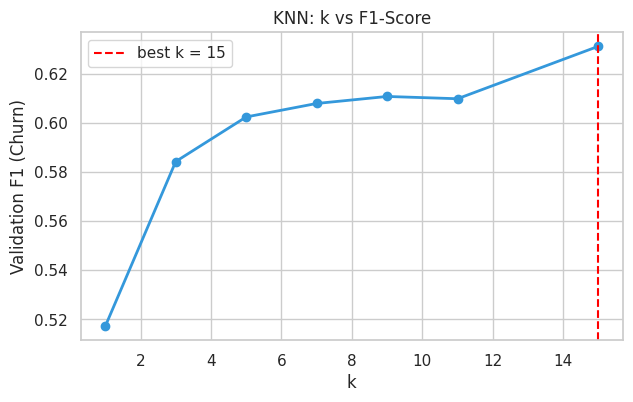

{1: np.float64(0.5172), 3: np.float64(0.5843), 5: np.float64(0.6024), 7: np.float64(0.6079), 9: np.float64(0.6107), 11: np.float64(0.6098), 15: np.float64(0.6312)}
➡ Best k = 15


,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),AUC-ROC,Train Time (s)
KNN k=15,0.7459,0.5089,0.8482,0.6362,0.8447,0.0048


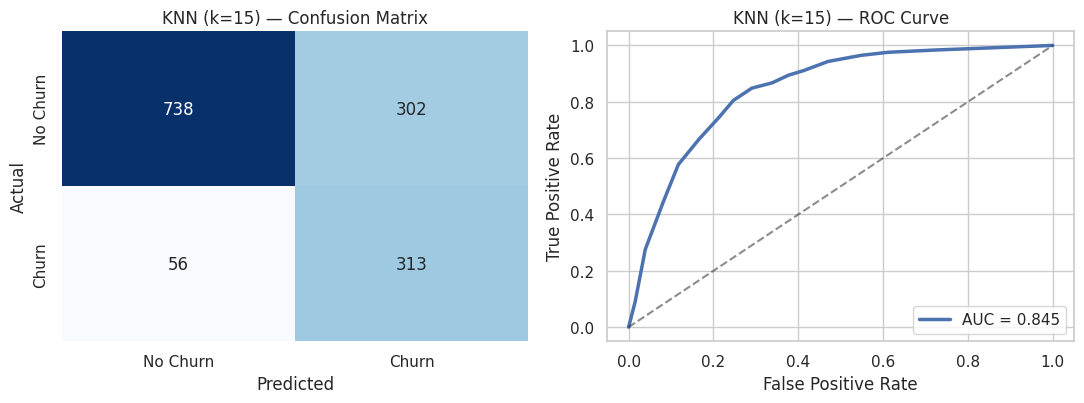

In [16]:
t0 = time.perf_counter(); knn5 = KNeighborsClassifier(n_neighbors=5).fit(X_train_sm, y_train_sm); t5 = time.perf_counter() - t0
m5, _, _ = evaluate('KNN (k=5)', knn5, X_test, y_test, t5, store=False)
print('KNN baseline (k=5):'); display(pd.DataFrame([m5], index=['KNN k=5']).round(4))
# tune k on a validation split carved out of the TRAIN set (SMOTE only on the inner-train part)
X_tr_in, X_val, y_tr_in, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=RS)
X_tr_in_sm, y_tr_in_sm = SMOTE(random_state=RS).fit_resample(X_tr_in, y_tr_in)
k_list = [1, 3, 5, 7, 9, 11, 15]; val_f1 = []
for k in k_list:
    mk = KNeighborsClassifier(n_neighbors=k).fit(X_tr_in_sm, y_tr_in_sm); val_f1.append(f1_score(y_val, mk.predict(X_val)))
best_k = k_list[int(np.argmax(val_f1))]
plt.figure(figsize=(7, 4)); plt.plot(k_list, val_f1, 'o-', lw=2, color='#3498db'); plt.axvline(best_k, color='red', ls='--', label=f'best k = {best_k}')
plt.xlabel('k'); plt.ylabel('Validation F1 (Churn)'); plt.title('KNN: k vs F1-Score'); plt.legend(); plt.show()
print(dict(zip(k_list, np.round(val_f1, 4)))); print(f'➡ Best k = {best_k}')
t0 = time.perf_counter(); knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_sm, y_train_sm); tk = time.perf_counter() - t0
m, yp, ypr = evaluate('KNN', knn, X_test, y_test, tk); display(pd.DataFrame([m], index=[f'KNN k={best_k}']).round(4)); plot_cm_roc(f'KNN (k={best_k})', y_test, yp, ypr)

### 4.2 Naive Bayes — Gaussian NB

,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),AUC-ROC,Train Time (s)
GaussianNB,0.7672,0.5358,0.832,0.6518,0.86,0.0097


class_prior_ (trained on SMOTE-balanced data): [0.5 0.5]
class_prior_ (trained on original train data): [0.739 0.261]
Actual churn rate in training set           : 0.261  -> priors match only when NB is trained on the ORIGINAL data; SMOTE forces 50/50.


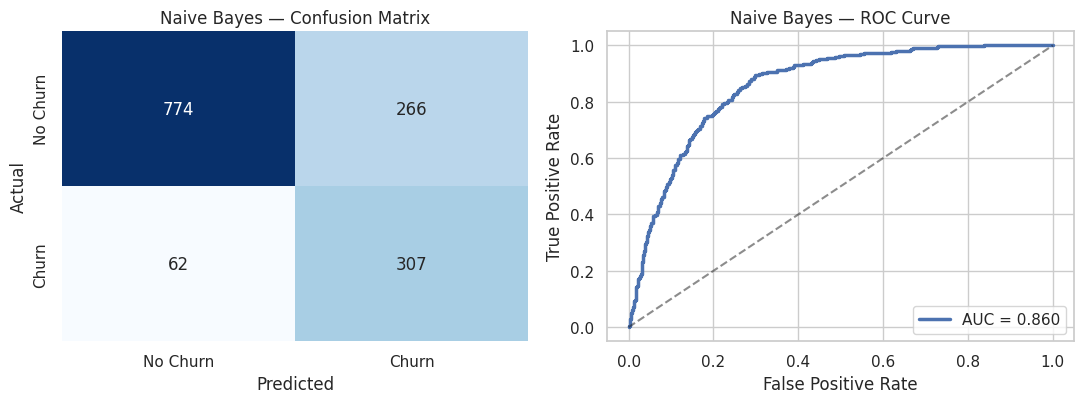

corr(tenure, TotalCharges) = 0.79


In [17]:
t0 = time.perf_counter(); nb = GaussianNB().fit(X_train_sm, y_train_sm); tnb = time.perf_counter() - t0
m, yp, ypr = evaluate('Naive Bayes', nb, X_test, y_test, tnb); display(pd.DataFrame([m], index=['GaussianNB']).round(4))
print('class_prior_ (trained on SMOTE-balanced data):', nb.class_prior_.round(3))
print('class_prior_ (trained on original train data):', GaussianNB().fit(X_train, y_train).class_prior_.round(3))
print(f'Actual churn rate in training set           : {y_train.mean():.3f}  -> priors match only when NB is trained on the ORIGINAL data; SMOTE forces 50/50.')
plot_cm_roc('Naive Bayes', y_test, yp, ypr)
print(f'corr(tenure, TotalCharges) = {X_train_raw["tenure"].corr(X_train_raw["TotalCharges"]):.2f}')

**Does the independence assumption hold?** No — `tenure`, `MonthlyCharges`, `TotalCharges` and `num_services` are clearly correlated (TotalCharges ≈ tenure × MonthlyCharges), and one-hot dummies of the same variable are mutually exclusive. NB therefore tends to be over-confident, but it still ranks customers reasonably and tends to give **high recall**.

> 💡 For churn, a **False Negative** (predicting "No Churn" for a customer who leaves) costs far more than a False Positive — so the analysis below focuses on **Recall for the Churn class**.

## 📊 Step 5: Model Building — SVM & Decision Tree
### 5.1 Support Vector Machine

SVM baseline (RBF, C=1):


,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),AUC-ROC,Train Time (s)
SVM C=1,0.7963,0.5876,0.7453,0.6571,0.8535,8.1881


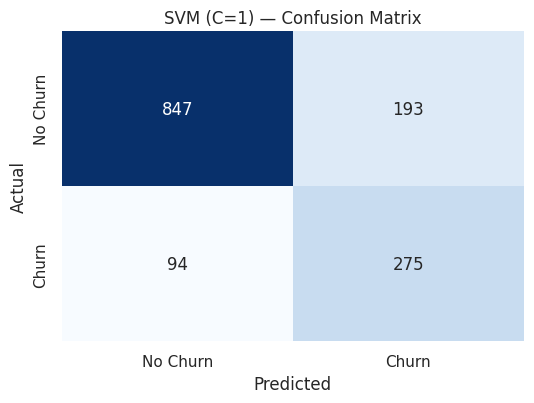

In [18]:
t0 = time.perf_counter(); svm0 = SVC(kernel='rbf', C=1, gamma='scale', probability=True, random_state=RS).fit(X_train_sm, y_train_sm); t_s0 = time.perf_counter() - t0
m0, yp0, _ = evaluate('SVM (C=1)', svm0, X_test, y_test, t_s0, store=False)
print('SVM baseline (RBF, C=1):'); display(pd.DataFrame([m0], index=['SVM C=1']).round(4)); plot_cm_roc('SVM (C=1)', y_test, yp0)

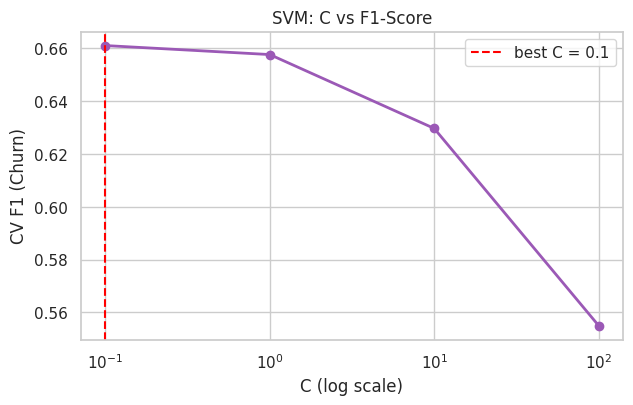

{0.1: np.float64(0.661), 1: np.float64(0.6576), 10: np.float64(0.6296), 100: np.float64(0.555)}
➡ Best C = 0.1


,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),AUC-ROC,Train Time (s)
SVM C=0.1,0.77,0.5404,0.8157,0.6501,0.8659,9.4204


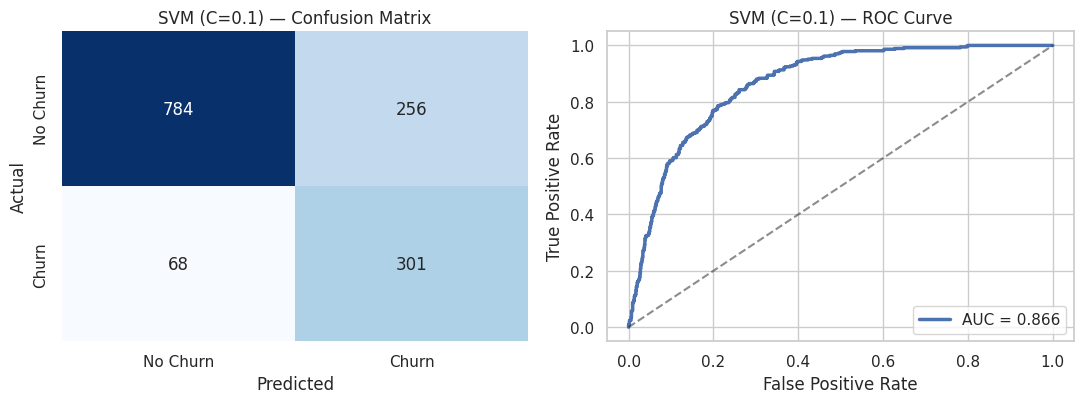

In [19]:
# tune C with 3-fold CV (SMOTE inside each fold -> no leakage)
C_list = [0.1, 1, 10, 100]; c_f1 = []
for Cv in C_list:
    pipe = ImbPipeline([('smote', SMOTE(random_state=RS)), ('svc', SVC(kernel='rbf', C=Cv, gamma='scale'))])
    c_f1.append(cross_val_score(pipe, X_train, y_train, cv=3, scoring='f1').mean())
best_C = C_list[int(np.argmax(c_f1))]
plt.figure(figsize=(7, 4)); plt.semilogx(C_list, c_f1, 'o-', lw=2, color='#9b59b6'); plt.axvline(best_C, color='red', ls='--', label=f'best C = {best_C}')
plt.xlabel('C (log scale)'); plt.ylabel('CV F1 (Churn)'); plt.title('SVM: C vs F1-Score'); plt.legend(); plt.show()
print(dict(zip(C_list, np.round(c_f1, 4)))); print(f'➡ Best C = {best_C}')
t0 = time.perf_counter(); svm = SVC(kernel='rbf', C=best_C, gamma='scale', probability=True, random_state=RS).fit(X_train_sm, y_train_sm); t_s = time.perf_counter() - t0
m, yp, ypr = evaluate('SVM', svm, X_test, y_test, t_s); display(pd.DataFrame([m], index=[f'SVM C={best_C}']).round(4)); plot_cm_roc(f'SVM (C={best_C})', y_test, yp, ypr)

**Interpretability vs performance:** the RBF-SVM is a black box — it cannot tell the retention team *why* a customer is flagged, and scoring is slower than a tree; in exchange it can capture non-linear interactions. If its recall/AUC gain over the tree is small, the business may prefer the transparent model.

### 5.2 Decision Tree Classifier

Decision Tree (max_depth=5, class_weight=balanced):


,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),AUC-ROC,Train Time (s)
DT depth=5,0.7466,0.5094,0.878,0.6448,0.8587,0.0168


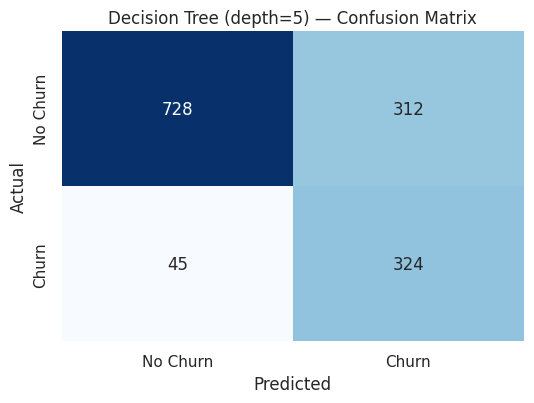

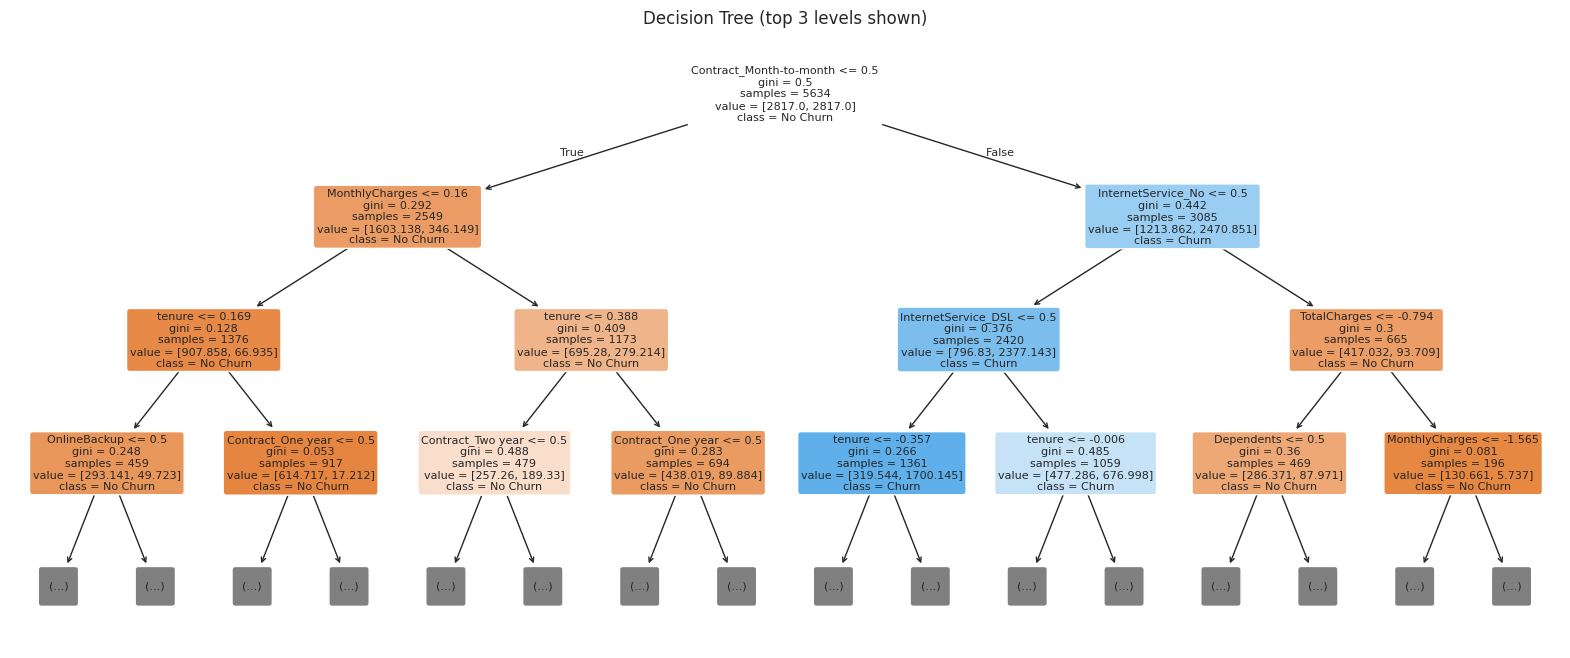

➡ Root split feature: Contract_Month-to-month  (threshold 0.500, on the scaled/encoded value)


In [20]:
t0 = time.perf_counter(); dt = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=RS).fit(X_train, y_train); t_d0 = time.perf_counter() - t0
md0, ydt0, _ = evaluate('DT (depth=5)', dt, X_test, y_test, t_d0, store=False)
print('Decision Tree (max_depth=5, class_weight=balanced):'); display(pd.DataFrame([md0], index=['DT depth=5']).round(4)); plot_cm_roc('Decision Tree (depth=5)', y_test, ydt0)
plt.figure(figsize=(20, 8)); plot_tree(dt, max_depth=3, feature_names=list(X_train.columns), class_names=['No Churn','Churn'], filled=True, rounded=True, fontsize=8)
plt.title('Decision Tree (top 3 levels shown)'); plt.show()
print(f'➡ Root split feature: {X_train.columns[dt.tree_.feature[0]]}  (threshold {dt.tree_.threshold[0]:.3f}, on the scaled/encoded value)')

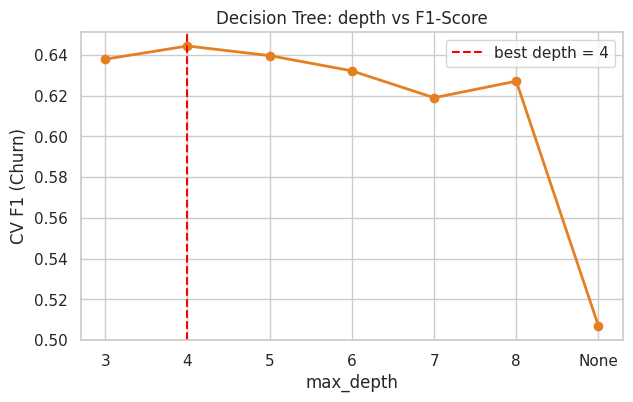

{'3': np.float64(0.638), '4': np.float64(0.6444), '5': np.float64(0.6397), '6': np.float64(0.6322), '7': np.float64(0.619), '8': np.float64(0.6271), 'None': np.float64(0.5068)}
➡ Best max_depth = 4


,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),AUC-ROC,Train Time (s)
DT depth=4,0.7615,0.5282,0.8374,0.6478,0.8566,0.0131


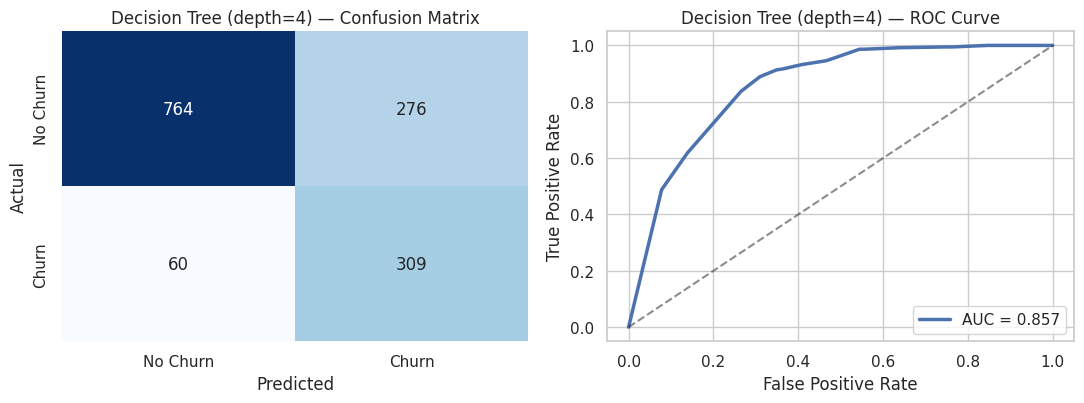

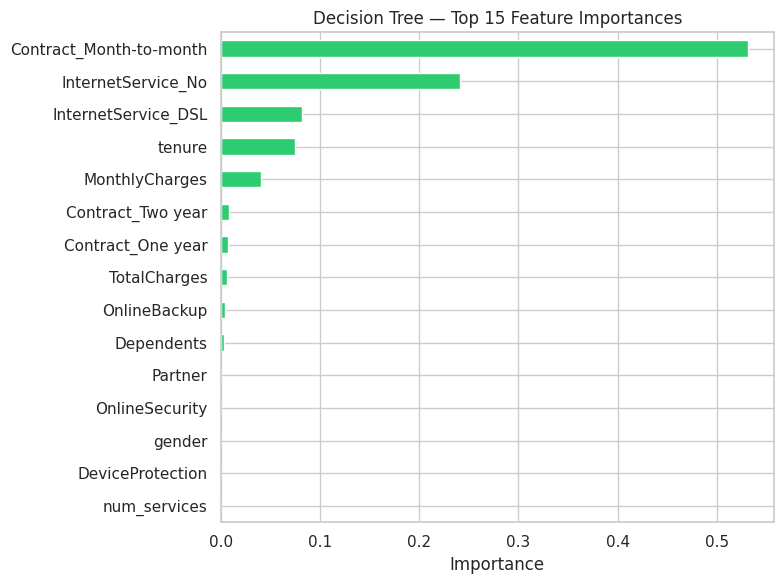

In [21]:
depths = [3, 4, 5, 6, 7, 8, None]; d_f1 = []
for d in depths:
    d_f1.append(cross_val_score(DecisionTreeClassifier(max_depth=d, class_weight='balanced', random_state=RS), X_train, y_train, cv=5, scoring='f1').mean())
best_depth = depths[int(np.argmax(d_f1))]
plt.figure(figsize=(7, 4)); plt.plot([str(d) for d in depths], d_f1, 'o-', lw=2, color='#e67e22'); plt.axvline(str(best_depth), color='red', ls='--', label=f'best depth = {best_depth}')
plt.xlabel('max_depth'); plt.ylabel('CV F1 (Churn)'); plt.title('Decision Tree: depth vs F1-Score'); plt.legend(); plt.show()
print(dict(zip([str(d) for d in depths], np.round(d_f1, 4)))); print(f'➡ Best max_depth = {best_depth}')
t0 = time.perf_counter(); dt_final = DecisionTreeClassifier(max_depth=best_depth, class_weight='balanced', random_state=RS).fit(X_train, y_train); t_d = time.perf_counter() - t0
m, yp, ypr = evaluate('Decision Tree', dt_final, X_test, y_test, t_d); display(pd.DataFrame([m], index=[f'DT depth={best_depth}']).round(4)); plot_cm_roc(f'Decision Tree (depth={best_depth})', y_test, yp, ypr)
imp_series = pd.Series(dt_final.feature_importances_, index=X_train.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 6)); imp_series.head(15).sort_values().plot(kind='barh', color='#2ecc71'); plt.title('Decision Tree — Top 15 Feature Importances'); plt.xlabel('Importance'); plt.tight_layout(); plt.show()

### 5.3 One model: `class_weight='balanced'` vs SMOTE

In [22]:
# KNN & GaussianNB have no class_weight parameter, so the comparison uses the better of SVM / Decision Tree (by churn recall)
cand = max(['SVM', 'Decision Tree'], key=lambda n: results[n]['Recall (Churn)'])
if cand == 'SVM':
    m_sm = SVC(kernel='rbf', C=best_C, gamma='scale', random_state=RS).fit(X_train_sm, y_train_sm)
    m_cw = SVC(kernel='rbf', C=best_C, gamma='scale', class_weight='balanced', random_state=RS).fit(X_train, y_train)
else:
    m_sm = DecisionTreeClassifier(max_depth=best_depth, random_state=RS).fit(X_train_sm, y_train_sm)
    m_cw = DecisionTreeClassifier(max_depth=best_depth, class_weight='balanced', random_state=RS).fit(X_train, y_train)
rows = {}
for lbl, mdl in [('SMOTE-augmented data', m_sm), ('class_weight="balanced" (original data)', m_cw)]:
    p = mdl.predict(X_test); rows[lbl] = {'Recall (Churn)': recall_score(y_test, p), 'Precision (Churn)': precision_score(y_test, p), 'F1 (Churn)': f1_score(y_test, p)}
cmp53 = pd.DataFrame(rows).T.round(4); print(f'Model compared: {cand}'); display(cmp53)
better = cmp53['Recall (Churn)'].idxmax()
print(f'➡ Higher churn Recall: {better}  (Δ recall = {cmp53["Recall (Churn)"].max() - cmp53["Recall (Churn)"].min():.4f})')

Model compared: Decision Tree


,Recall (Churn),Precision (Churn),F1 (Churn)
SMOTE-augmented data,0.8320,0.5302,0.6477
"class_weight=""balanced"" (original data)",0.8374,0.5282,0.6478


➡ Higher churn Recall: class_weight="balanced" (original data)  (Δ recall = 0.0054)


## 📈 Step 6: Model Evaluation & Comparison

Consolidated comparison — sorted by Recall (Churn), descending:


,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),AUC-ROC,Train Time (s)
KNN,0.7459,0.5089,0.8482,0.6362,0.8447,0.0048
Decision Tree,0.7615,0.5282,0.8374,0.6478,0.8566,0.0131
Naive Bayes,0.7672,0.5358,0.8320,0.6518,0.8600,0.0097
SVM,0.7700,0.5404,0.8157,0.6501,0.8659,9.4204


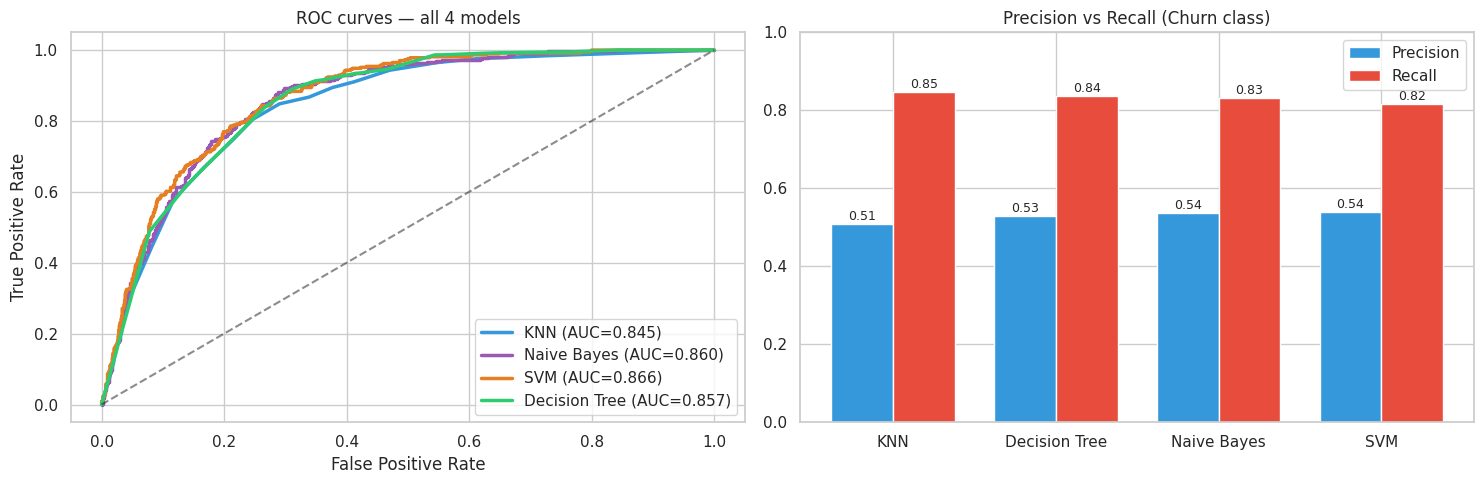

In [23]:
comp = pd.DataFrame(results).T[['Accuracy','Precision (Churn)','Recall (Churn)','F1 (Churn)','AUC-ROC','Train Time (s)']].sort_values('Recall (Churn)', ascending=False).round(4)
print('Consolidated comparison — sorted by Recall (Churn), descending:'); display(comp)
fig, ax = plt.subplots(1, 2, figsize=(15, 5)); cols = {'KNN':'#3498db','Naive Bayes':'#9b59b6','SVM':'#e67e22','Decision Tree':'#2ecc71'}
for name, pr in probas.items():
    fpr, tpr, _ = roc_curve(y_test, pr); ax[0].plot(fpr, tpr, lw=2.5, color=cols[name], label=f'{name} (AUC={roc_auc_score(y_test, pr):.3f})')
ax[0].plot([0,1],[0,1],'k--',alpha=.5); ax[0].set_xlabel('False Positive Rate'); ax[0].set_ylabel('True Positive Rate'); ax[0].set_title('ROC curves — all 4 models'); ax[0].legend(loc='lower right')
x = np.arange(len(comp)); w = 0.38
ax[1].bar(x - w/2, comp['Precision (Churn)'], w, label='Precision', color='#3498db'); ax[1].bar(x + w/2, comp['Recall (Churn)'], w, label='Recall', color='#e74c3c')
ax[1].set_xticks(x); ax[1].set_xticklabels(comp.index); ax[1].set_ylim(0, 1); ax[1].set_title('Precision vs Recall (Churn class)'); ax[1].legend()
for i, (p, r) in enumerate(zip(comp['Precision (Churn)'], comp['Recall (Churn)'])):
    ax[1].text(i - w/2, p + .01, f'{p:.2f}', ha='center', fontsize=9); ax[1].text(i + w/2, r + .01, f'{r:.2f}', ha='center', fontsize=9)
plt.tight_layout(); plt.show()

In [24]:
# Selection rule (Recall first, then interpretability & latency): models within 2 recall-points of the best AND Precision >= 0.45 are treated as equally good at catching churners;
# among those we deploy the most interpretable / fastest one.
interp_rank = {'Decision Tree': 0, 'Naive Bayes': 1, 'SVM': 2, 'KNN': 3}
pool = comp[(comp['Precision (Churn)'] >= 0.45) & (comp['Recall (Churn)'] >= comp['Recall (Churn)'].max() - 0.02)]
deploy_name = sorted(pool.index, key=lambda n: (interp_rank[n], -pool.loc[n, 'F1 (Churn)']))[0] if len(pool) else comp.index[0]
r = comp.loc[deploy_name]; y_dep = fitted[deploy_name].predict(X_test)
flagged = int(y_dep.sum()); caught = int(((y_dep == 1) & (y_test.values == 1)).sum()); total_ch = int(y_test.sum())
interp = {'KNN':'low (instance-based, slow to score on a large subscriber base)', 'Naive Bayes':'medium (simple probabilistic model, very fast)',
          'SVM':'low (black box, slower scoring)', 'Decision Tree':'high (readable if/else rules the retention team can audit)'}
print('RECOMMENDATION')
print(f'1. Deploy the **{deploy_name}** for the retention team: it catches {r["Recall (Churn)"]:.1%} of churners (Recall) with Precision {r["Precision (Churn)"]:.1%}, F1 {r["F1 (Churn)"]:.3f} and AUC {r["AUC-ROC"]:.3f}.')
print(f'2. On the {len(y_test):,} test customers it flags {flagged} ({flagged/len(y_test):.1%}) and correctly catches {caught} of the {total_ch} real churners.')
print(f'3. Interpretability: {interp[deploy_name]}; training time {r["Train Time (s)"]:.2f}s.')
print(f'4. Best raw Recall overall is {comp.index[0]} ({comp.iloc[0]["Recall (Churn)"]:.1%}); best AUC is {comp["AUC-ROC"].idxmax()} ({comp["AUC-ROC"].max():.3f}).')
print(f'5. Selection rule: a missed churner (FN) costs more than a wasted offer (FP), so Recall comes first; models within 2 recall-points of the best ({comp["Recall (Churn)"].max():.1%}) are treated as equivalent, and among them we pick the most interpretable / lowest-latency one with Precision >= 45% (limited calls/day).')

RECOMMENDATION
1. Deploy the **Decision Tree** for the retention team: it catches 83.7% of churners (Recall) with Precision 52.8%, F1 0.648 and AUC 0.857.
2. On the 1,409 test customers it flags 585 (41.5%) and correctly catches 309 of the 369 real churners.
3. Interpretability: high (readable if/else rules the retention team can audit); training time 0.01s.
4. Best raw Recall overall is KNN (84.8%); best AUC is SVM (0.866).
5. Selection rule: a missed churner (FN) costs more than a wasted offer (FP), so Recall comes first; models within 2 recall-points of the best (84.8%) are treated as equivalent, and among them we pick the most interpretable / lowest-latency one with Precision >= 45% (limited calls/day).


## 🔍 Step 7: Error Analysis & Interpretation
### 7.1 Error Analysis on the best (recommended) model

In [25]:
y_pred = fitted[deploy_name].predict(X_test); fn_mask = (y_test.values == 1) & (y_pred == 0)
contract_cols = [c for c in X_test_raw.columns if c.startswith('Contract_')]
contract_lbl = X_test_raw[contract_cols].idxmax(axis=1).str.replace('Contract_', '')
def profile(mask):
    sub = X_test_raw[mask]
    return pd.Series({'count': int(mask.sum()), 'avg tenure (months)': sub['tenure'].mean(), 'avg MonthlyCharges': sub['MonthlyCharges'].mean(),
                      '% Month-to-month': (contract_lbl[mask] == 'Month-to-month').mean() * 100})
prof = pd.DataFrame({'False Negatives (missed churners)': profile(fn_mask), 'All actual churners': profile(y_test.values == 1), 'All customers': profile(np.ones(len(y_test), bool))}).round(2)
print(f'Model analysed: {deploy_name}  |  False Negatives: {int(fn_mask.sum())} of {int(y_test.sum())} churners'); display(prof)
fn, ch = prof['False Negatives (missed churners)'], prof['All actual churners']
print('\nPattern:')
print(f'- Missed churners have {"HIGHER" if fn["avg tenure (months)"] > ch["avg tenure (months)"] else "LOWER"} tenure ({fn["avg tenure (months)"]:.1f} vs {ch["avg tenure (months)"]:.1f} months for all churners).')
print(f'- Their MonthlyCharges are {"HIGHER" if fn["avg MonthlyCharges"] > ch["avg MonthlyCharges"] else "LOWER"} ({fn["avg MonthlyCharges"]:.1f} vs {ch["avg MonthlyCharges"]:.1f}).')
print(f'- Only {fn["% Month-to-month"]:.0f}% are Month-to-month vs {ch["% Month-to-month"]:.0f}% of all churners -> the model misses churners who do NOT look like the typical high-risk profile (longer contracts / more loyal-looking customers).')

Model analysed: Decision Tree  |  False Negatives: 60 of 369 churners


,False Negatives (missed churners),All actual churners,All customers
count,60.00,369.00,1409.00
avg tenure (months),24.75,14.79,29.60
avg MonthlyCharges,69.46,84.20,68.65
% Month-to-month,40.00,90.24,56.07



Pattern:
- Missed churners have HIGHER tenure (24.8 vs 14.8 months for all churners).
- Their MonthlyCharges are LOWER (69.5 vs 84.2).
- Only 40% are Month-to-month vs 90% of all churners -> the model misses churners who do NOT look like the typical high-risk profile (longer contracts / more loyal-looking customers).


### 7.2 Feature Importance / Decision Insight

In [26]:
meaning = {
 'tenure': ('Months with the company', 'Short-tenure customers are the most fragile -> run a 90-day onboarding/welcome programme.'),
 'tenure_group_enc': ('Tenure band (New/Mid/Senior/Loyal)', 'Target the "New" band with early-life offers.'),
 'MonthlyCharges': ('Monthly bill', 'Higher bills raise churn risk -> offer plan right-sizing or loyalty discounts.'),
 'TotalCharges': ('Lifetime spend (proxy for tenure x bill)', 'Low lifetime spend = young account -> treat like a new customer.'),
 'Contract_Month-to-month': ('No lock-in contract', 'Offer incentives to migrate to 1/2-year contracts.'),
 'Contract_Two year': ('2-year lock-in', 'Strongest protective factor -> push upgrades.'),
 'Contract_One year': ('1-year lock-in', 'Moderately protective -> upsell to 2-year.'),
 'InternetService_Fiber optic': ('Fiber optic customers', 'Fiber users churn more -> check price/quality and support experience.'),
 'InternetService_DSL': ('DSL customers', 'Lower-risk internet segment.'), 'InternetService_No': ('Phone-only customers', 'Very low churn segment.'),
 'OnlineSecurity': ('Has online-security add-on', 'Bundling security/support add-ons increases stickiness.'), 'TechSupport': ('Has tech-support add-on', 'Offer free tech-support trials to at-risk users.'),
 'num_services': ('Number of add-on services', 'More add-ons = stickier customer -> cross-sell bundles.'),
 'PaymentMethod_Electronic check': ('Pays by electronic check', 'Nudge to auto-pay with a small incentive.'), 'AutoPay': ('Automatic payment enabled', 'Auto-pay customers are more loyal -> promote it.'),
 'PaperlessBilling': ('Paperless billing', 'Digital-first users are easier to churn -> engage digitally.'), 'SeniorCitizen': ('Senior citizen flag', 'Tailor assisted-support offers.'),
}
top5 = imp_series.head(5)
print('Top 5 split features of the Decision Tree:\n')
for f, v in top5.items():
    mn, act = meaning.get(f, ('Behavioural / billing signal', 'Review with the retention team.')); print(f'• {f}  (importance {v:.3f}) — {mn}. Action: {act}')
fiber_rate = churn_num[df['InternetService']=='Fiber optic'].mean()*100; echeck_rate = churn_num[df['PaymentMethod']=='Electronic check'].mean()*100
m2m, two = contract_rate['Month-to-month'], contract_rate['Two year']
print('\nBusiness-friendly takeaways:')
print(f'• Month-to-month customers churn at {m2m:.1f}% vs {two:.1f}% on 2-year contracts ({m2m/max(two, 0.01):.1f}x higher) — the contract appears at the top of the tree.')
print(f'• Customers in their first year churn at {tenure_rate["0-12"]:.1f}% vs {tenure_rate["49-72"]:.1f}% after 4 years — retention effort should be front-loaded.')
print(f'• Fiber optic users churn at {fiber_rate:.1f}% and electronic-check payers at {echeck_rate:.1f}% (overall {churn_num.mean()*100:.1f}%) — price/quality and payment friction are levers.')
print(f'• The high-risk segment (Month-to-month, above-median bill, tenure <= 12) churns at {churn_num[seg].mean():.1%} — the first list the retention team should call.')

Top 5 split features of the Decision Tree:

• Contract_Month-to-month  (importance 0.531) — No lock-in contract. Action: Offer incentives to migrate to 1/2-year contracts.
• InternetService_No  (importance 0.241) — Phone-only customers. Action: Very low churn segment.
• InternetService_DSL  (importance 0.082) — DSL customers. Action: Lower-risk internet segment.
• tenure  (importance 0.075) — Months with the company. Action: Short-tenure customers are the most fragile -> run a 90-day onboarding/welcome programme.
• MonthlyCharges  (importance 0.041) — Monthly bill. Action: Higher bills raise churn risk -> offer plan right-sizing or loyalty discounts.

Business-friendly takeaways:
• Month-to-month customers churn at 41.9% vs 3.2% on 2-year contracts (13.1x higher) — the contract appears at the top of the tree.
• Customers in their first year churn at 46.8% vs 5.0% after 4 years — retention effort should be front-loaded.
• Fiber optic users churn at 40.9% and electronic-check payers at 3

In [27]:
# (Optional bonus) permutation importance — only meaningful when SVM is the recommended model
if deploy_name == 'SVM':
    idx = np.random.RandomState(RS).choice(len(X_test), 600, replace=False)
    pi = permutation_importance(fitted['SVM'], X_test.iloc[idx], y_test.iloc[idx], scoring='recall', n_repeats=3, random_state=RS, n_jobs=-1)
    pis = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False).head(10)
    plt.figure(figsize=(8, 5)); pis.sort_values().plot(kind='barh', color='#e67e22'); plt.title('SVM — Permutation Importance (top 10, scoring=recall)'); plt.tight_layout(); plt.show()
else:
    print(f'Bonus skipped: the recommended model is {deploy_name} (permutation importance is only requested when SVM is the best model).')

Bonus skipped: the recommended model is Decision Tree (permutation importance is only requested when SVM is the best model).


## 🚀 Step 8: Pipeline, Deployment & GitHub Submission
### 8.1 Save the final pipeline

In [28]:
final_model = fitted[deploy_name]
pipeline = Pipeline([('prep', prep), ('model', final_model)])      # raw encoded features -> scaling -> model
joblib.dump(pipeline, 'churn_model.pkl'); print('✅ saved churn_model.pkl  (pipeline = StandardScaler preprocessor + ' + deploy_name + ')')
loaded = joblib.load('churn_model.pkl')
sample = X_test_raw.sample(5, random_state=RS)
proba = loaded.predict_proba(sample)[:, 1]; label = loaded.predict(sample)
out = pd.DataFrame({'P(churn)': proba.round(3), 'Predicted': np.where(label == 1, 'CHURN', 'Retained'), 'Actual': np.where(y_test.loc[sample.index] == 1, 'CHURN', 'Retained')}, index=sample.index)
print('\nPredictions for 5 sample customers from the reloaded pickle:'); display(out)

✅ saved churn_model.pkl  (pipeline = StandardScaler preprocessor + Decision Tree)

Predictions for 5 sample customers from the reloaded pickle:


,P(churn),Predicted,Actual
2456,0.635,CHURN,Retained
2747,0.281,Retained,Retained
1595,0.051,Retained,Retained
724,0.635,CHURN,CHURN
6446,0.341,Retained,Retained


### 8.2 GitHub submission
```bash
git init && git add CustomerChurn_SupervisedLearning.ipynb churn_model.pkl summary_report.md requirements.txt README.md
git commit -m "Telco churn - supervised learning"
git branch -M main
git remote add origin https://github.com/<your-username>/telco-churn-supervised-learning.git
git push -u origin main
```

### 8.3 Summary report (`summary_report.md`) & `requirements.txt` — generated from this notebook's results

In [29]:
top3 = list(imp_series.head(3).index)
sig = '\n'.join([f'{i+1}. **{f}** — {meaning.get(f, ("behavioural signal", "review with team"))[0]}. Action: {meaning.get(f, ("", "review with the retention team"))[1]}' for i, f in enumerate(top3)])
report = f"""# Summary Report — Telco Customer Churn (Supervised Learning, Set B)

## 1. Business problem & dataset
A telecom operator is losing paying subscribers every month and cannot tell who is about to leave. We use the IBM Telco-style dataset of {len(df):,} customers and 21 columns (demographics, services, contract, billing) with a binary target `Churn` ({churn_rate:.1%} churners). Because acquiring a new subscriber (CAC) costs far more than retaining one, ranking likely churners lets the retention team protect customer lifetime value (CLV) with a limited daily call budget.

## 2. Preprocessing & class-imbalance strategy
`customerID` was dropped and the 11 blank `TotalCharges` values (brand-new customers with tenure 0) were converted to numeric and filled with the median. We engineered `tenure_group`, `num_services` and `AutoPay`, binary-mapped Yes/No columns, one-hot encoded InternetService, Contract and PaymentMethod, and standardised tenure, MonthlyCharges, TotalCharges and num_services. After a stratified 80/20 split (random_state=42) the scaler was fit on training data only, and SMOTE was applied to the training set only (class_weight='balanced' was compared for SVM/Decision Tree). The test set was never touched.

## 3. Recommended model
We recommend the **{deploy_name}**: Recall (churn) {r['Recall (Churn)']:.1%}, Precision {r['Precision (Churn)']:.1%}, F1 {r['F1 (Churn)']:.3f}, AUC-ROC {r['AUC-ROC']:.3f}. It flags {flagged} of {len(y_test):,} test customers and catches {caught} of {total_ch} real churners. A missed churner (false negative) costs far more than a wasted offer, so we optimise Recall while keeping Precision high enough for the ~500-calls-per-day capacity. Interpretability: {interp[deploy_name]}.

## 4. Top 3 churn signals and recommended actions
{sig}

## 5. Next steps
Collect richer behavioural data (call-centre complaints, data usage, network quality), test gradient boosting / ensembles and a small neural network, calibrate probabilities, and expose the saved pipeline through a real-time scoring API (FastAPI) with monthly retraining and drift monitoring.
"""
open('summary_report.md', 'w', encoding='utf-8').write(report)
open('requirements.txt', 'w').write('pandas\nnumpy\nscikit-learn\nimbalanced-learn\nmatplotlib\nseaborn\njoblib\njupyter\n')
print(f'✅ summary_report.md written ({len(report.split())} words) and requirements.txt written')

✅ summary_report.md written (325 words) and requirements.txt written


## ✅ Conclusion
All steps of the exam are implemented and executed: problem framing, EDA, preprocessing (leak-free), KNN / Naive Bayes / SVM / Decision Tree with tuning, SMOTE vs class_weight, Recall-focused comparison, error analysis, business insights, a saved sklearn pipeline and auto-generated report.